In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")
df = df.drop_duplicates().dropna()

X = pd.get_dummies(
    df.drop("target", axis=1),
    drop_first=True
).astype(float).values

y = df["target"].astype(int).values

rng = np.random.default_rng(42)

train_idx = []
val_idx = []
test_idx = []

for cls in np.unique(y):
    indices = np.where(y == cls)[0]
    rng.shuffle(indices)

    n = len(indices)
    n_train = int(n * 0.60)
    n_val = int(n * 0.20)

    train_idx.extend(indices[:n_train])
    val_idx.extend(indices[n_train:n_train + n_val])
    test_idx.extend(indices[n_train + n_val:])

train_idx = np.array(train_idx)
val_idx = np.array(val_idx)
test_idx = np.array(test_idx)

rng.shuffle(train_idx)
rng.shuffle(val_idx)
rng.shuffle(test_idx)

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std == 0] = 1

X_train = (X_train - mean) / std
X_val = (X_val - mean) / std
X_test = (X_test - mean) / std

In [3]:
def metrics(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))

    accuracy = (tp + tn) / len(y_true)
    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    }

In [4]:
class ManualLogisticRegression:
    def __init__(self, learning_rate=0.05, epochs=600, l2=0.01):
        self.lr = learning_rate
        self.epochs = epochs
        self.l2 = l2

    def sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = y.reshape(-1, 1)

        self.weights = np.zeros((X.shape[1], 1))
        self.bias = 0.0
        n = len(y)

        for _ in range(self.epochs):
            p = self.sigmoid(X @ self.weights + self.bias)

            dw = X.T @ (p - y) / n + self.l2 * self.weights
            db = np.mean(p - y)

            self.weights -= self.lr * dw
            self.bias -= self.lr * db

        return self

    def predict_proba(self, X):
        return self.sigmoid(
            X @ self.weights + self.bias
        ).ravel()

    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)

In [5]:
class ManualDecisionTree:
    def __init__(self, max_depth=3, min_samples=5):
        self.max_depth = max_depth
        self.min_samples = min_samples

    def gini(self, y):
        if len(y) == 0:
            return 0
        p = np.mean(y)
        return 2 * p * (1 - p)

    def find_split(self, X, y):
        best_gain = 0
        best_feature = None
        best_threshold = None
        parent = self.gini(y)
        n = len(y)

        for j in range(X.shape[1]):
            values = np.unique(X[:, j])

            if len(values) > 20:
                values = np.percentile(
                    values, np.linspace(5, 95, 10)
                )

            for threshold in values:
                left = X[:, j] <= threshold
                right = ~left

                if left.sum() < self.min_samples:
                    continue
                if right.sum() < self.min_samples:
                    continue

                child = (
                    left.sum() / n * self.gini(y[left])
                    + right.sum() / n * self.gini(y[right])
                )

                gain = parent - child

                if gain > best_gain:
                    best_gain = gain
                    best_feature = j
                    best_threshold = threshold

        return best_feature, best_threshold

    def build(self, X, y, depth):
        node = {"probability": float(np.mean(y))}

        if (
            depth >= self.max_depth
            or len(y) < 2 * self.min_samples
            or len(np.unique(y)) == 1
        ):
            return node

        feature, threshold = self.find_split(X, y)

        if feature is None:
            return node

        left = X[:, feature] <= threshold
        right = ~left

        node["feature"] = feature
        node["threshold"] = threshold
        node["left"] = self.build(X[left], y[left], depth + 1)
        node["right"] = self.build(X[right], y[right], depth + 1)

        return node

    def fit(self, X, y):
        self.tree = self.build(X, y, 0)
        return self

    def probability_one(self, row, node):
        if "feature" not in node:
            return node["probability"]

        if row[node["feature"]] <= node["threshold"]:
            return self.probability_one(row, node["left"])

        return self.probability_one(row, node["right"])

    def predict_proba(self, X):
        return np.array([
            self.probability_one(row, self.tree)
            for row in X
        ])

    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)

In [6]:
class ManualKNN:
    def __init__(self, k=5):
        self.k = k

    def fit(self, X, y):
        self.X = np.asarray(X)
        self.y = np.asarray(y)
        return self

    def predict_proba(self, X):
        results = []

        for row in X:
            distances = np.sqrt(
                np.sum((self.X - row) ** 2, axis=1)
            )

            nearest = np.argsort(distances)[:self.k]
            results.append(np.mean(self.y[nearest]))

        return np.array(results)

    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)

In [7]:
models = {
    "Logistic Regression": ManualLogisticRegression(
        learning_rate=0.05,
        epochs=600,
        l2=0.01
    ),
    "Decision Tree": ManualDecisionTree(
        max_depth=3,
        min_samples=5
    ),
    "k-NN": ManualKNN(k=5)
}

for model in models.values():
    model.fit(X_train, y_train)

print("All base classifiers trained successfully.")

All base classifiers trained successfully.


In [8]:
validation_probabilities = {}
validation_predictions = {}
validation_f1 = {}

for name, model in models.items():
    probabilities = model.predict_proba(X_val)
    predictions = (probabilities >= 0.5).astype(int)

    validation_probabilities[name] = probabilities
    validation_predictions[name] = predictions

    score = metrics(y_val, predictions)
    validation_f1[name] = score["F1 Score"]

    print(
        f"{name}: Validation F1 = "
        f"{score['F1 Score']:.4f}"
    )


raw_weights = {
    name: score + 1e-6
    for name, score in validation_f1.items()
}

weight_total = sum(raw_weights.values())

weights = {
    name: value / weight_total
    for name, value in raw_weights.items()
}

print("\nDynamic Model Weights")

for name, weight in weights.items():
    print(f"{name}: {weight:.4f}")

Logistic Regression: Validation F1 = 0.8333
Decision Tree: Validation F1 = 0.6944
k-NN: Validation F1 = 0.7941

Dynamic Model Weights
Logistic Regression: 0.3589
Decision Tree: 0.2991
k-NN: 0.3420


In [9]:
test_probabilities = {}
test_predictions = {}

for name, model in models.items():
    test_probabilities[name] = model.predict_proba(X_test)
    test_predictions[name] = (
        test_probabilities[name] >= 0.5
    ).astype(int)

In [10]:
hard_vote_matrix = np.column_stack([
    test_predictions[name]
    for name in models
])


hard_vote = (
    hard_vote_matrix.sum(axis=1) > len(models) / 2
).astype(int)


weighted_hard_scores = np.zeros(len(y_test))

for name in models:
    weighted_hard_scores += (
        weights[name] * test_predictions[name]
    )

weighted_hard_vote = (
    weighted_hard_scores > 0.5
).astype(int)

In [11]:
soft_probabilities = np.mean(
    np.column_stack([
        test_probabilities[name]
        for name in models
    ]),
    axis=1
)

soft_vote = (soft_probabilities >= 0.5).astype(int)

weighted_soft_probabilities = np.zeros(len(y_test))

for name in models:
    weighted_soft_probabilities += (
        weights[name] * test_probabilities[name]
    )

weighted_soft_vote = (
    weighted_soft_probabilities >= 0.5
).astype(int)

In [12]:
results = []

for name in models:
    predictions = test_predictions[name]

    results.append({
        "Method": name,
        **metrics(y_test, predictions)
    })

voting_methods = {
    "Hard Voting": hard_vote,
    "Weighted Hard Voting": weighted_hard_vote,
    "Soft Voting": soft_vote,
    "Weighted Soft Voting": weighted_soft_vote
}

for name, predictions in voting_methods.items():
    results.append({
        "Method": name,
        **metrics(y_test, predictions)
    })

results_df = pd.DataFrame(results)

print("\nFinal Test Performance")
print(results_df.round(4).to_string(index=False))

results_df.to_csv(
    "manual_voting_classifier_results.csv",
    index=False
)


Final Test Performance
              Method  Accuracy  Precision  Recall  F1 Score
 Logistic Regression    0.8730     0.8824  0.8824    0.8824
       Decision Tree    0.7619     0.8065  0.7353    0.7692
                k-NN    0.8730     0.8824  0.8824    0.8824
         Hard Voting    0.8730     0.8824  0.8824    0.8824
Weighted Hard Voting    0.8730     0.8824  0.8824    0.8824
         Soft Voting    0.8254     0.8485  0.8235    0.8358
Weighted Soft Voting    0.8254     0.8485  0.8235    0.8358


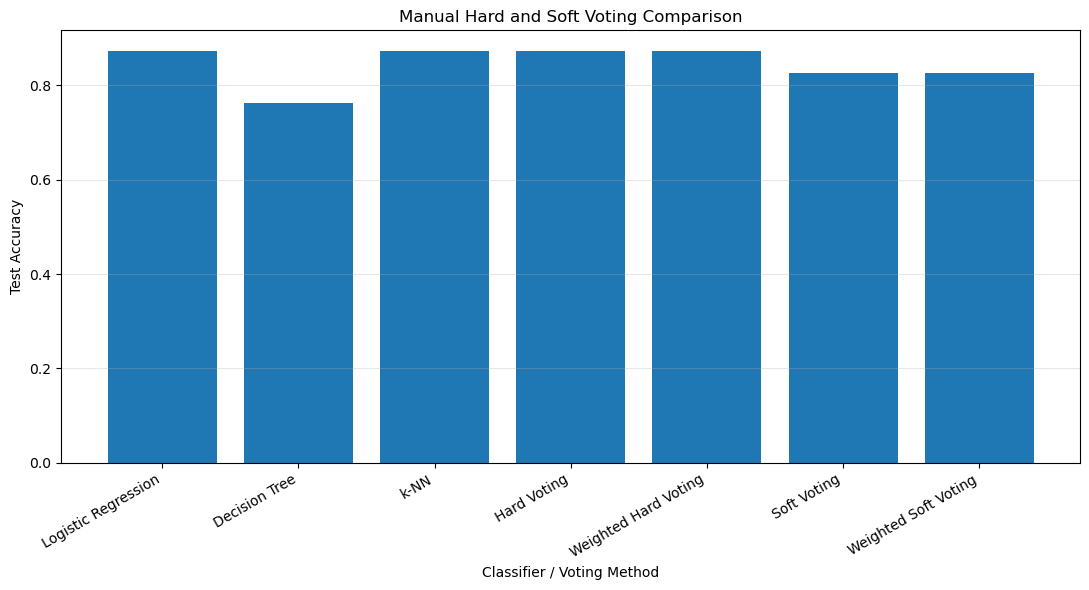

In [13]:
plt.figure(figsize=(11, 6))

plt.bar(
    results_df["Method"],
    results_df["Accuracy"]
)

plt.xlabel("Classifier / Voting Method")
plt.ylabel("Test Accuracy")
plt.title("Manual Hard and Soft Voting Comparison")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

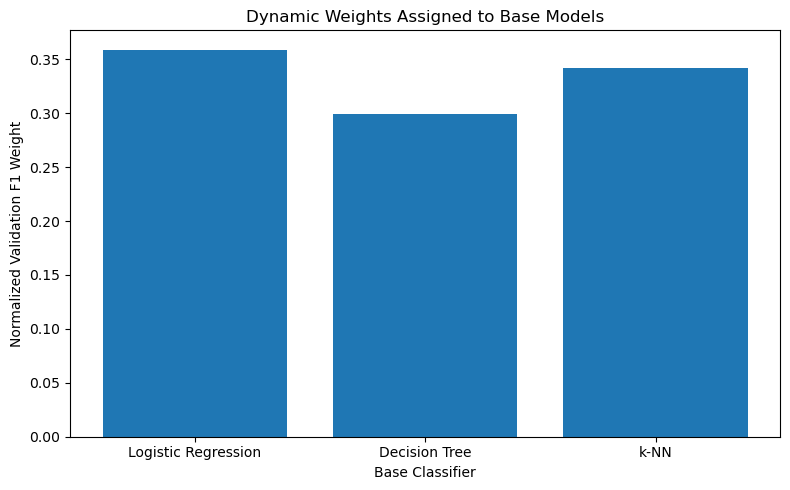

In [14]:
plt.figure(figsize=(8, 5))

plt.bar(
    list(weights.keys()),
    list(weights.values())
)

plt.xlabel("Base Classifier")
plt.ylabel("Normalized Validation F1 Weight")
plt.title("Dynamic Weights Assigned to Base Models")
plt.tight_layout()
plt.show()

In [15]:
for name, predictions in voting_methods.items():
    tn = np.sum((y_test == 0) & (predictions == 0))
    fp = np.sum((y_test == 0) & (predictions == 1))
    fn = np.sum((y_test == 1) & (predictions == 0))
    tp = np.sum((y_test == 1) & (predictions == 1))

    cm = np.array([
        [tn, fp],
        [fn, tp]
    ])

    print(f"\n{name} Confusion Matrix")
    print("Rows: Actual 0, Actual 1")
    print("Columns: Predicted 0, Predicted 1")
    print(cm)

print("\nResults saved to manual_voting_classifier_results.csv")


Hard Voting Confusion Matrix
Rows: Actual 0, Actual 1
Columns: Predicted 0, Predicted 1
[[25  4]
 [ 4 30]]

Weighted Hard Voting Confusion Matrix
Rows: Actual 0, Actual 1
Columns: Predicted 0, Predicted 1
[[25  4]
 [ 4 30]]

Soft Voting Confusion Matrix
Rows: Actual 0, Actual 1
Columns: Predicted 0, Predicted 1
[[24  5]
 [ 6 28]]

Weighted Soft Voting Confusion Matrix
Rows: Actual 0, Actual 1
Columns: Predicted 0, Predicted 1
[[24  5]
 [ 6 28]]

Results saved to manual_voting_classifier_results.csv
